# M2.4 · 因子合成与择时

> 单个因子各有强弱和周期，合成把多个因子整合为一个综合打分，择时则根据因子近期表现动态调整权重。
> 本节实操等权、IC 加权、ICIR 最大化合成与滚动择时，比较合成效果。

## 一、合成方法

| 方法 | 逻辑 |
|---|---|
| 等权 | 标准化后简单平均，稳健、不依赖历史 |
| IC 加权 | 按历史 IC 均值加权，IC 高的权重大 |
| ICIR 最大化 | w∝Σ_IC^-1 μ_IC，兼顾收益与稳定性 |
| 因子择时 | 用近期 IC 滚动调整权重，表现好的因子加权 |

## 二、加载数据并准备因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import hfactors, combine
from factor_lab.evaluate import ic_series, ic_summary, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument')
hf = hfactors.build_hf_factors(op, cl, hi, lo, vo)
names = ['已实现波动20','日内动量20','尾盘位置20','量价相关20']
facs = [hf[n] for n in names]
fwd1 = fwd_returns(cl, 1)
ic_hist = pd.concat([ic_series(f, fwd1).rename(n)
                     for f, n in zip(facs, names)], axis=1).dropna()
print('IC 历史:', ic_hist.shape)

[26932:MainThread](2026-11-05 16:36:09,578) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[26932:MainThread](2026-11-05 16:36:11,693) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[26932:MainThread](2026-11-05 16:36:11,695) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


IC 历史: (2120, 4)


## 三、三种合成方法对比

In [2]:
eq = combine.equal_combine(facs)
icw = combine.ic_weight_combine(facs, ic_hist.mean().values)
icir = combine.icir_combine(facs, ic_hist)
comp = {'等权': eq, 'IC加权': icw, 'ICIR最大化': icir}
rows = []
for name, cdf in comp.items():
    s = ic_summary(ic_series(cdf, fwd1))
    rows.append({'方法': name, 'IC': s['IC均值'], 'IR': s['IR'], '胜率': s['IC胜率']})
cres = pd.DataFrame(rows).set_index('方法')
print(cres.round(4).to_string())
print()
print('ICIR 权重:')
print(combine.icir_weights(ic_hist).round(3).to_string())

             IC      IR      胜率
方法                             
等权       0.0059  0.0275  0.5057
IC加权     0.0255  0.1253  0.5580
ICIR最大化  0.0205  0.1308  0.5467

ICIR 权重:
已实现波动20    0.179
日内动量20     0.176
尾盘位置20    -0.219
量价相关20     0.427


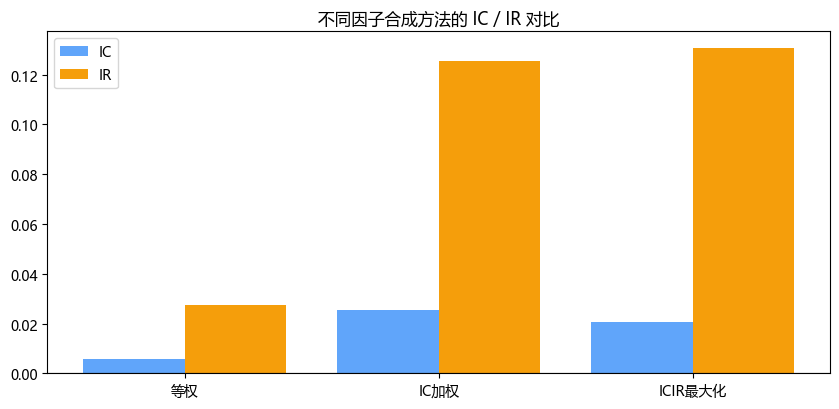

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(8.5,4.2))
x = np.arange(len(cres))
ax.bar(x-0.2, cres['IC'], 0.4, label='IC', color='#60a5fa')
ax.bar(x+0.2, cres['IR'], 0.4, label='IR', color='#f59e0b')
ax.axhline(0, color='#333', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(cres.index)
ax.set_title('不同因子合成方法的 IC / IR 对比'); ax.legend()
plt.tight_layout(); plt.show()

## 四、因子择时：动态权重

In [4]:
tw = combine.timing_weights(ic_hist, window=60)
print('滚动择时权重（最后3期）:')
print(tw.tail(3).round(3).to_string())

滚动择时权重（最后3期）:
            已实现波动20  日内动量20  尾盘位置20  量价相关20
2026-10-28    0.094   0.203  -0.185   0.518
2026-10-29    0.067   0.207  -0.173   0.553
2026-10-30    0.076   0.205  -0.185   0.534


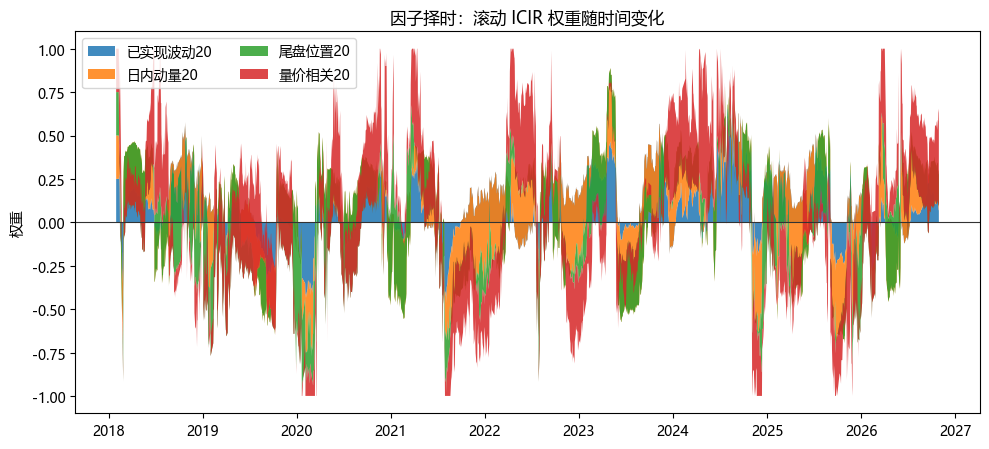

In [5]:
fig, ax = plt.subplots(figsize=(10,4.6))
ax.stackplot(tw.index, tw.T.values, labels=names, alpha=0.85)
ax.axhline(0, color='#333', lw=0.8)
ax.set_ylabel('权重'); ax.set_title('因子择时：滚动 ICIR 权重随时间变化')
ax.legend(loc='upper left', ncol=2); plt.tight_layout(); plt.show()

## 五、用择时权重构造动态合成因子

- 每个时点用当时的滚动权重对因子加权，得到动态综合因子；
- 择时的本质是因子动量（押注近期有效的因子），但可能在因子切换时失效，需控制换手；
- 实务中常以静态合成为主、择时作为小幅增强，避免过度拟合。

In [6]:
# 动态合成：逐时点加权（教学实现，取共同日期）
z = [combine.cross_zscore(f) for f in facs]
w = {n: tw[n].reindex(cl.index).ffill().fillna(1.0/len(names)) for n in names}
dyn = sum(z[i].mul(w[n], axis=0) for i, n in enumerate(names))
s = ic_summary(ic_series(dyn, fwd1))
print('动态择时合成 IC=%.4f IR=%.3f 胜率=%.3f' % (s['IC均值'], s['IR'], s['IC胜率']))

动态择时合成 IC=0.0382 IR=0.293 胜率=0.621


## 六、小结与面试要点

- 合成方法：等权稳健、IC 加权看历史效果、ICIR 最大化兼顾稳定性；择时用近期 IC 动态加权。
- 静态合成更稳健，择时是增强但有切换风险和过拟合可能。

**面试高频：**
- 等权和 IC 加权各有什么优劣？（答：等权稳健不依赖历史，IC加权利用效果但易受历史影响）
- ICIR 最大化权重怎么求？（答：w∝IC协方差逆×IC均值，再归一化）
- 因子择时为什么要谨慎？（答：本质因子动量，切换时失效、增加换手、易过拟合）
- 为什么实务常用等权？（答：简单稳健，历史权重估计误差大，等权样本外往往不差）

## 动手练习
1. 用三种方法合成因子并对比 IC/IR；
2. 画出择时权重变化，找出权重剧烈切换的时点；
3. 比较静态与动态合成的样本外表现，评估择时是否真有增益。

---
**M2 因子进阶（上）四个 notebook 全部完成。** 下一批 B3 进入 Barra、Fama-MacBeth 与挖掘前沿。